# Lab 5: K-Nearest Neighbor (KNN) for Classification and Regression
**Name:** Harshit Widhwani &nbsp;|&nbsp; **Section:** B &nbsp;|&nbsp; **Batch:** B4 &nbsp;|&nbsp; **Roll No:** 49  
**Course:** Machine Learning (ML-TP) 24CS03TH0501

## Part A: KNN Classification (Pima Indians Diabetes dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.datasets import load_diabetes
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

### Load and explore the dataset

In [2]:
df=pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

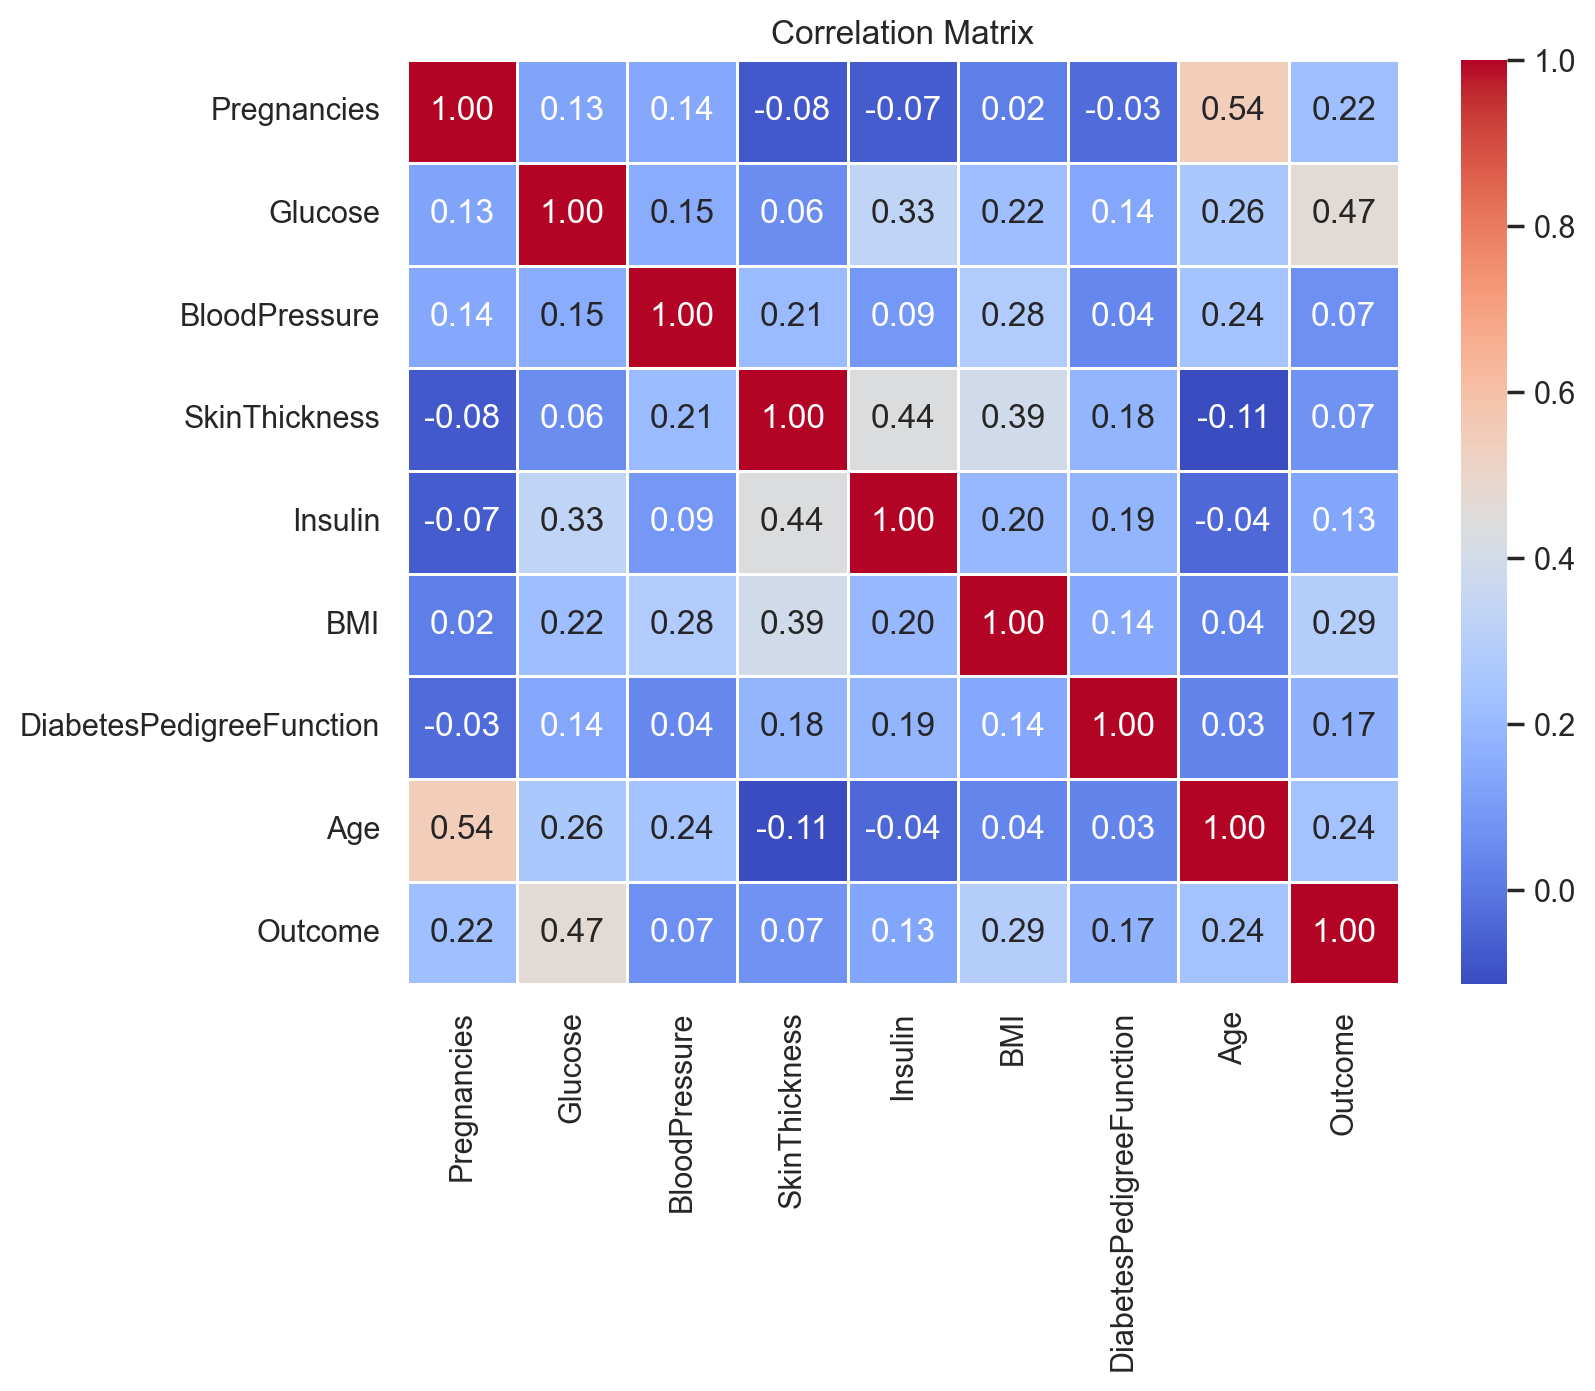

In [7]:
plt.figure(figsize=(8,6))
correlation=df.corr()
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

### Data preprocessing

In [8]:
zero_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts=(df[zero_columns]==0).sum()
print("Zero columns")
print(zero_counts)

Zero columns
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [9]:
df_clean=df.copy()
df_clean[zero_columns]=df_clean[zero_columns].replace(0,np.nan)
print("Missing values after replacing zeros:")
print(df_clean.isnull().sum())

Missing values after replacing zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [10]:
for col in zero_columns:
  df_clean[col]=df_clean[col].fillna(df_clean[col].median())
print("Missing values after median imputation:")
print(df_clean.isnull().sum())

Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [11]:
X=df_clean.drop("Outcome",axis=1)
y=df_clean["Outcome"]

print("X shape:",X.shape)
print("Y shape:",y.shape)

X shape: (768, 8)
Y shape: (768,)


In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 614
Testing samples: 154


In [13]:
print("Training distribution")
print(y_train.value_counts(normalize=True))

print("Testing distribution")
print(y_test.value_counts(normalize=True))

Training distribution
Outcome
0    0.653094
1    0.346906
Name: proportion, dtype: float64
Testing distribution
Outcome
0    0.642857
1    0.357143
Name: proportion, dtype: float64


In [14]:
scalar=StandardScaler()
X_train_scaled=scalar.fit_transform(X_train)
X_test_scaled=scalar.transform(X_test)

In [15]:
comparison=pd.DataFrame({
    "Original mean":X_train.mean(),
    "Original std":X_train.std(),
    "Scaled mean":X_train_scaled.mean(axis=0),
    "Scaled std":X_train_scaled.std(axis=0)
})
comparison.round(3)

,Original mean,Original std,Scaled mean,Scaled std
Pregnancies,3.743,3.313,0.0,1.0
Glucose,121.808,30.105,0.0,1.0
BloodPressure,72.230,12.099,-0.0,1.0
SkinThickness,28.712,8.412,0.0,1.0
Insulin,140.477,88.201,-0.0,1.0
BMI,32.352,6.936,-0.0,1.0
DiabetesPedigreeFunction,0.469,0.337,0.0,1.0
Age,32.907,11.503,-0.0,1.0


### KNN classifier (K = 5)

In [16]:
K=5
knn=KNeighborsClassifier(n_neighbors=K)
knn.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [17]:
y_pred=knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 1 1 0 0 1 0 0 1 0 0 0 0 0 0 1 1]


In [18]:
y_prob=knn.predict_proba(X_test_scaled)[:,1]
print("Predicted probability of Diabetes:")
print(y_prob[:20])

Predicted probability of Diabetes:
[0.8 0.4 0.  0.6 0.8 0.6 0.  0.4 0.6 0.2 0.4 0.8 0.2 0.4 0.  0.4 0.  0.
 1.  0.6]


In [19]:
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy: {accuracy:.4f}")
precision=precision_score(y_test,y_pred)
print(f"Precision: {precision:.4f}")
recall=recall_score(y_test,y_pred)
print(f"Recall: {recall:.4f}")
f1=f1_score(y_test,y_pred)
print(f"F1 score: {f1:.4f}")

Accuracy: 0.7208
Precision: 0.5968
Recall: 0.6727
F1 score: 0.6325


In [20]:
print(classification_report(y_test,y_pred,target_names=["No Diabetes","Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.75      0.77        99
    Diabetes       0.60      0.67      0.63        55

    accuracy                           0.72       154
   macro avg       0.70      0.71      0.70       154
weighted avg       0.73      0.72      0.72       154



In [21]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[74 25]
 [18 37]]


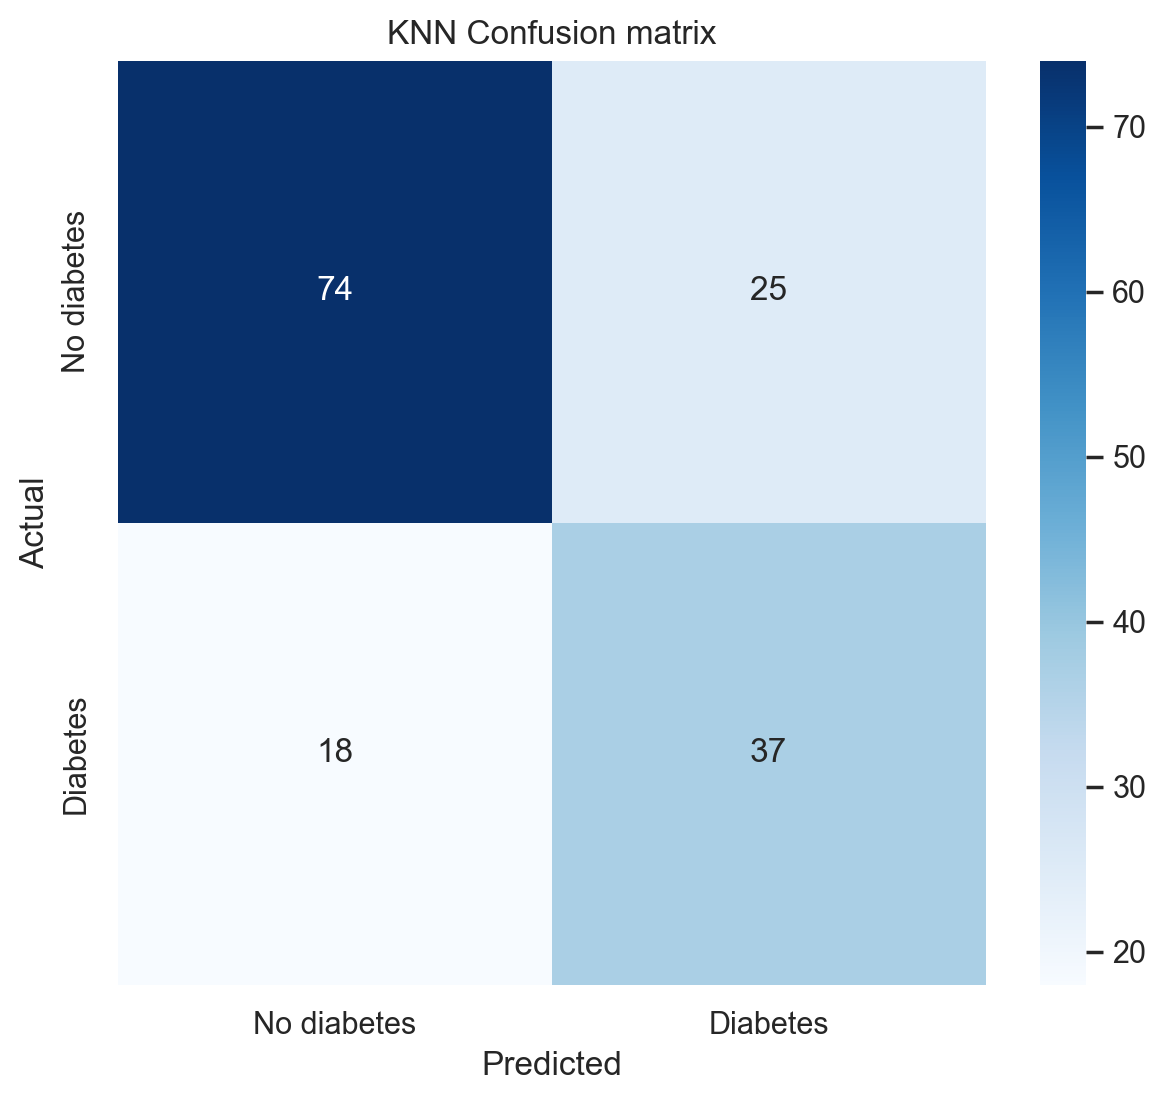

In [22]:
plt.figure(figsize=(7,6))

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No diabetes","Diabetes"],yticklabels=["No diabetes","Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion matrix")
plt.show()

### Choosing the best value of K

In [23]:
k_values=range(1,31)
train_accuracy=[]
test_accuracy=[]
for k in k_values:
  model=KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_scaled,y_train)
  train_accuracy.append(model.score(X_train_scaled,y_train))
  test_accuracy.append(model.score(X_test_scaled,y_test))

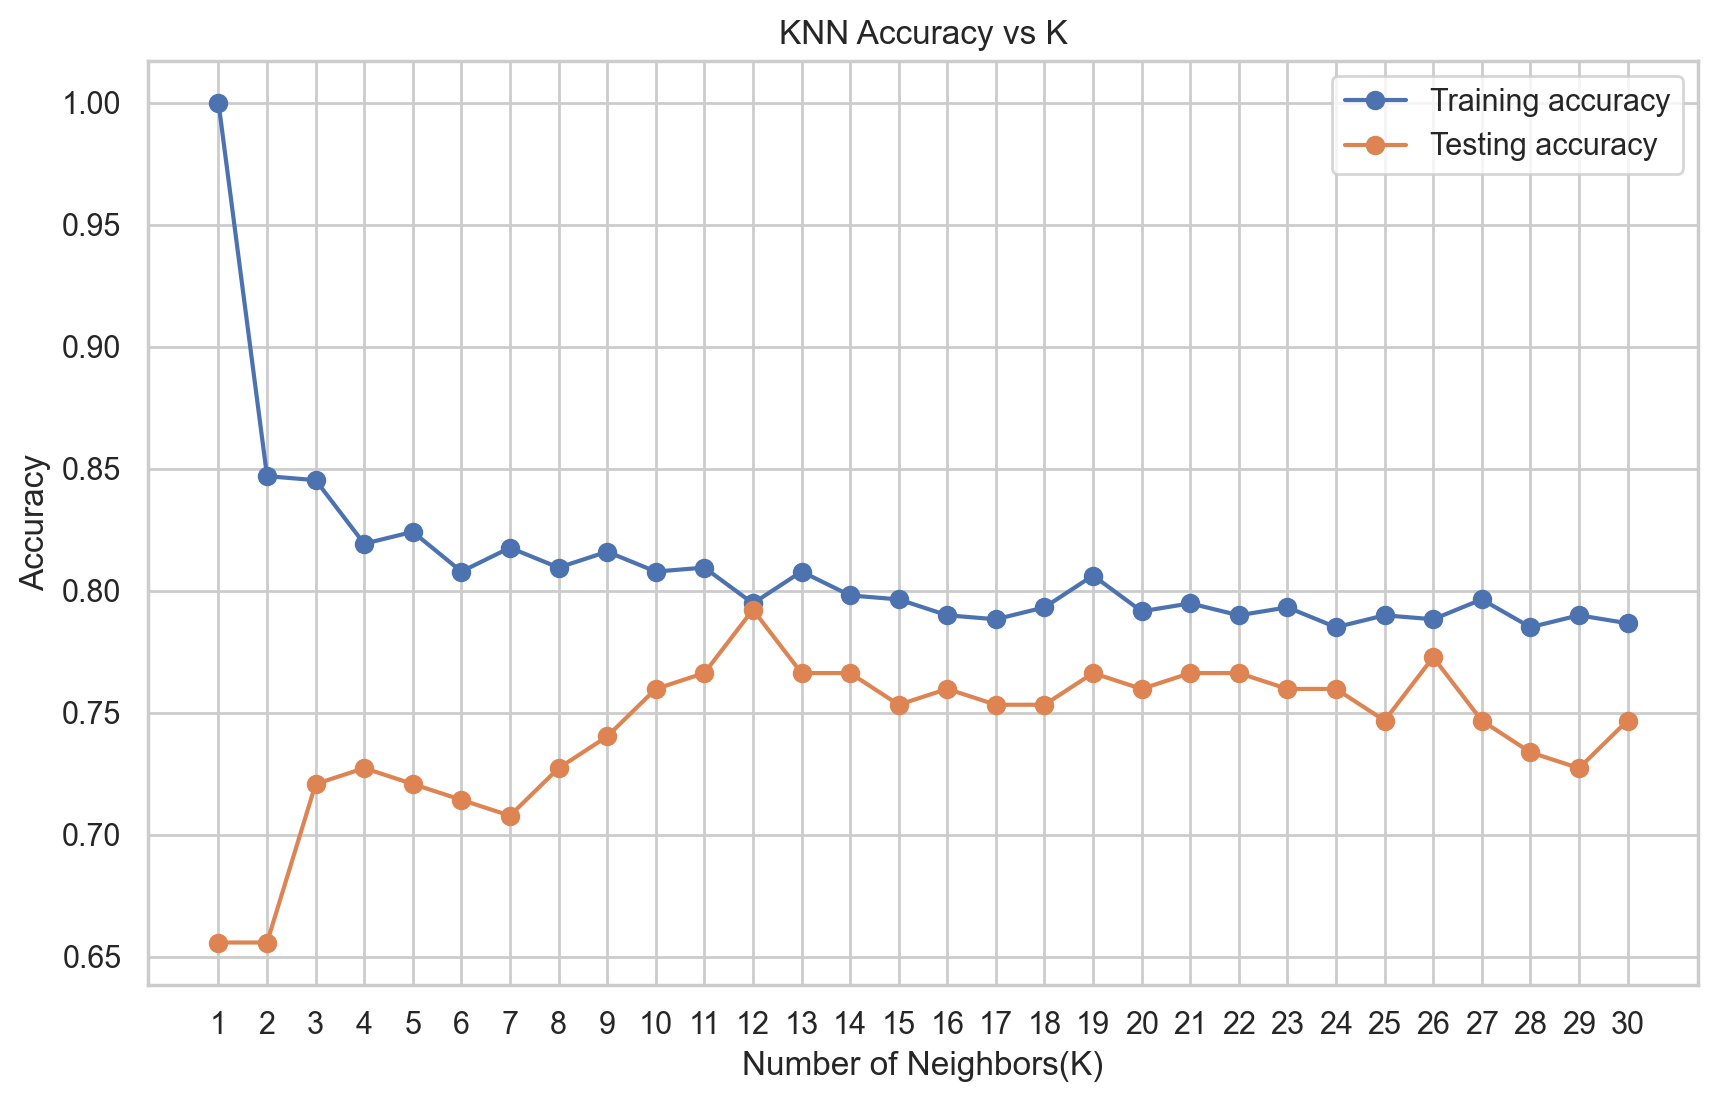

In [24]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,marker="o",label="Training accuracy")
plt.plot(k_values,test_accuracy,marker="o",label="Testing accuracy")
plt.xlabel("Number of Neighbors(K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(k_values)
plt.legend()
plt.show()

In [25]:
best_k_accuracy=k_values[np.argmax(test_accuracy)]
best_accuracy=max(test_accuracy)
print("Best K:",best_k_accuracy)
print("Best Accuracy:",best_accuracy)

Best K: 12
Best Accuracy: 0.7922077922077922


In [26]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_scores = []

for k in range(1, 31):

    model = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        model, X_train_scaled, y_train, cv=cv, scoring="accuracy"
    )

    cv_scores.append(scores.mean())

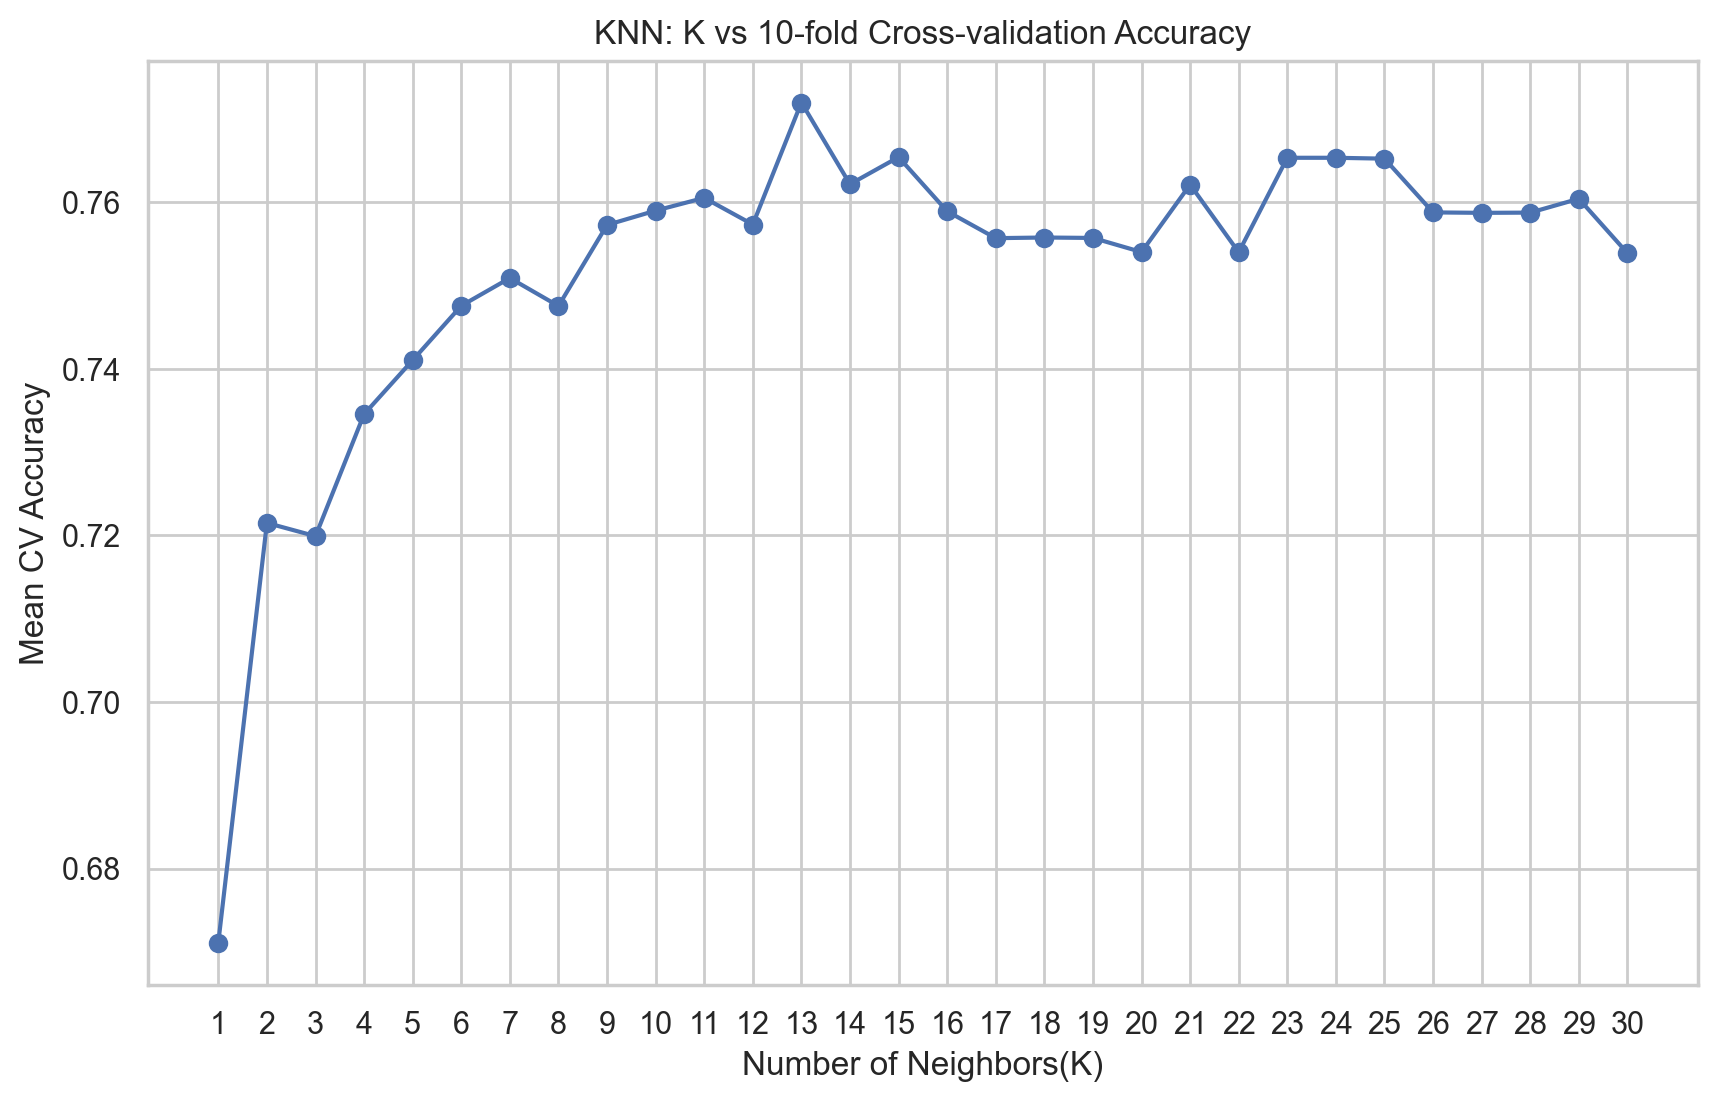

In [27]:
plt.figure(figsize=(10,6))
plt.plot(range(1, 31), cv_scores, marker="o")
plt.xlabel("Number of Neighbors(K)")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN: K vs 10-fold Cross-validation Accuracy")
plt.xticks(range(1, 31))
plt.show()

In [28]:
best_k_cv=np.argmax(cv_scores)+1
print("Best K based on cross validation:",best_k_cv)
print("Best cv Accuracy:",max(cv_scores))

Best K based on cross validation: 13
Best cv Accuracy: 0.7719725013220518


### Hyperparameter tuning using GridSearchCV

In [29]:
param_grid={
    "n_neighbors":list(range(3,31,2)),"weights":["uniform","distance"],
    "metric":["euclidean","manhattan","minkowski"],
    "p":[1,2]
}

In [30]:
grid_search=GridSearchCV(estimator=KNeighborsClassifier(),param_grid=param_grid,cv=5,scoring="accuracy",n_jobs=-1)
grid_search.fit(X_train_scaled,y_train)
print("Grid Search completed")

Grid Search completed


In [31]:
print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'metric': 'euclidean', 'n_neighbors': 23, 'p': 1, 'weights': 'uniform'}


In [32]:
print("Best Cross-validation Accuracy:",grid_search.best_score_)

Best Cross-validation Accuracy: 0.7753165400506464


In [33]:
best_knn=grid_search.best_estimator_
print("Test Accuracy of tuned KNN:",best_knn.score(X_test_scaled,y_test))

Test Accuracy of tuned KNN: 0.7597402597402597


## Part B: KNN Regression (Scikit-learn Diabetes dataset)

In [34]:
diabetes=load_diabetes(as_frame=True)
df_reg=diabetes.frame
print("Shape:",df_reg.shape)
df_reg.head()

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [35]:
X_reg=df_reg.drop("target",axis=1)
y_reg=df_reg["target"]

Xr_train,Xr_test,yr_train,yr_test=train_test_split(X_reg,y_reg,test_size=0.2,random_state=42)

reg_scaler=StandardScaler()
Xr_train_scaled=reg_scaler.fit_transform(Xr_train)
Xr_test_scaled=reg_scaler.transform(Xr_test)
print("Training samples:",Xr_train.shape[0])
print("Testing samples:",Xr_test.shape[0])

Training samples: 353
Testing samples: 89


In [36]:
knn_reg=KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(Xr_train_scaled,yr_train)
yr_pred=knn_reg.predict(Xr_test_scaled)

print("KNN Regression (K=5)")
print(f"MAE      : {mean_absolute_error(yr_test,yr_pred):.4f}")
print(f"MSE      : {mean_squared_error(yr_test,yr_pred):.4f}")
print(f"RMSE     : {np.sqrt(mean_squared_error(yr_test,yr_pred)):.4f}")
print(f"R2 Score : {r2_score(yr_test,yr_pred):.4f}")

KNN Regression (K=5)
MAE      : 42.7775
MSE      : 3047.4499
RMSE     : 55.2037
R2 Score : 0.4248


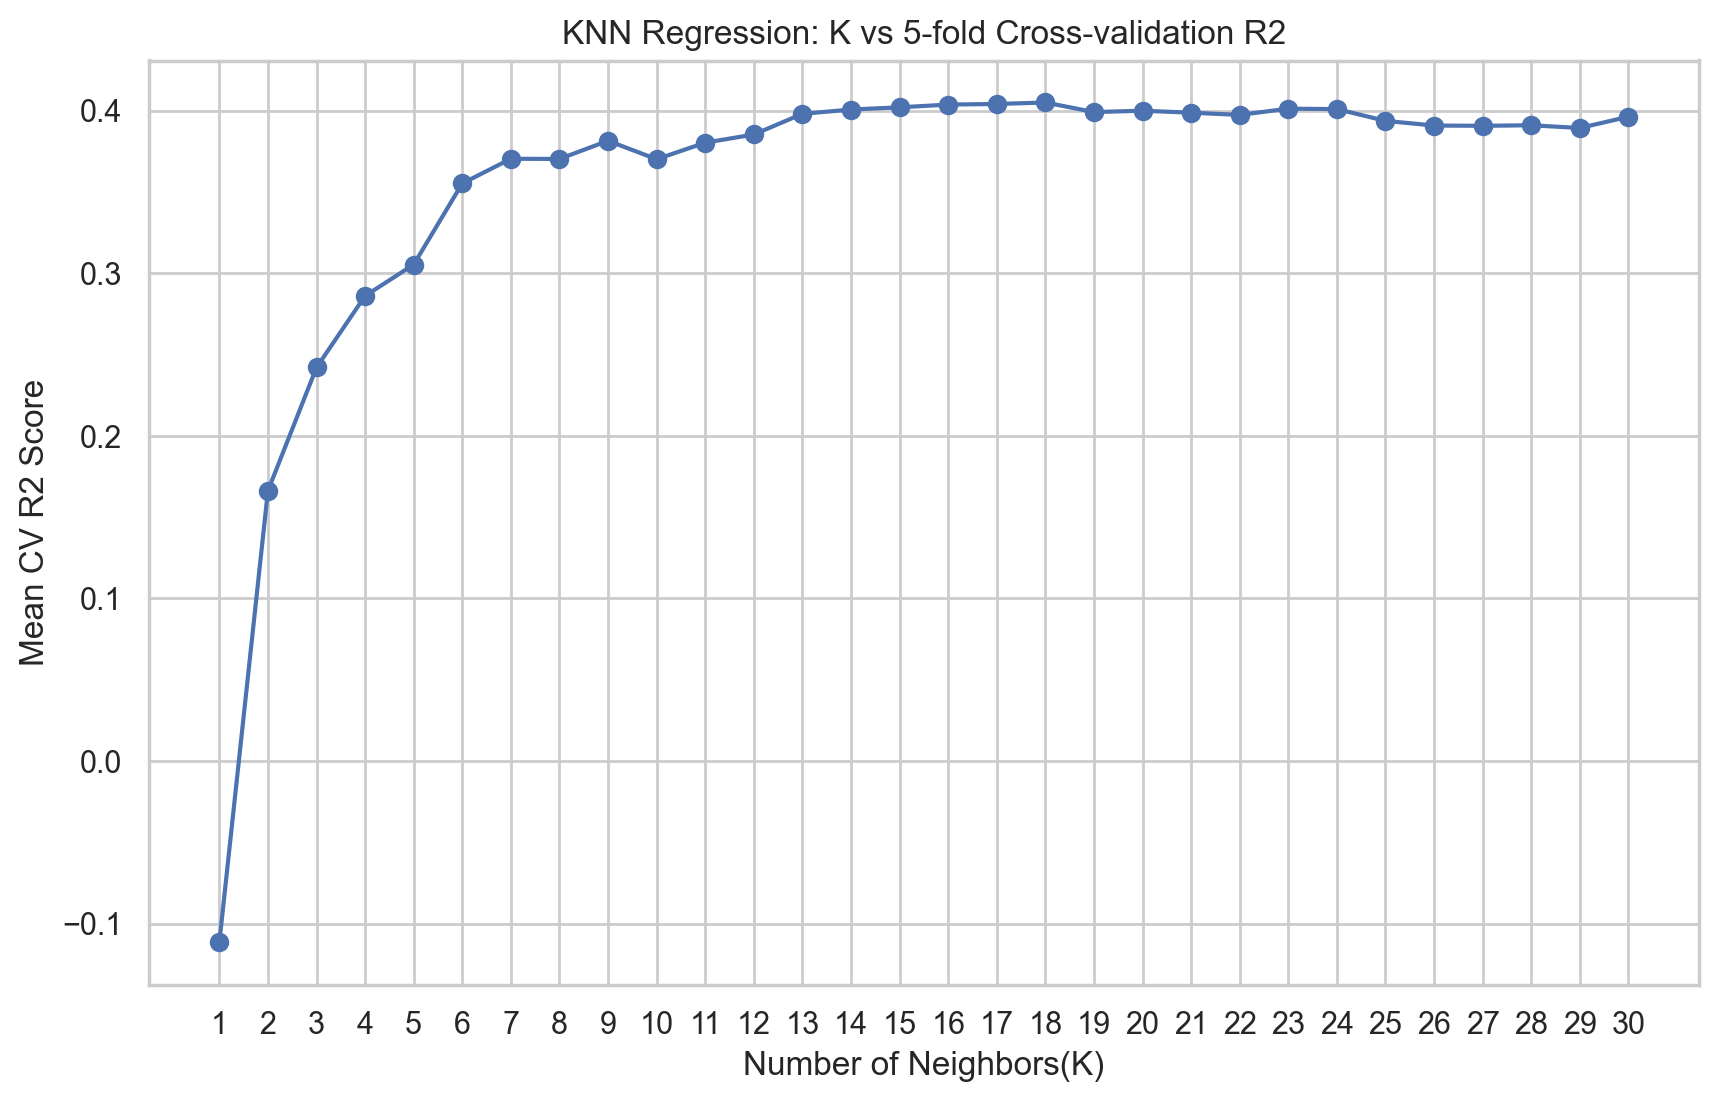

Best K for regression: 18
Best CV R2 Score: 0.4049856186244888


In [37]:
cv_r2=[]
for k in range(1,31):
  model=KNeighborsRegressor(n_neighbors=k)
  scores=cross_val_score(model,Xr_train_scaled,yr_train,cv=5,scoring="r2")
  cv_r2.append(scores.mean())

best_k_reg=np.argmax(cv_r2)+1
plt.figure(figsize=(10,6))
plt.plot(range(1,31),cv_r2,marker="o")
plt.xlabel("Number of Neighbors(K)")
plt.ylabel("Mean CV R2 Score")
plt.title("KNN Regression: K vs 5-fold Cross-validation R2")
plt.xticks(range(1,31))
plt.show()
print("Best K for regression:",best_k_reg)
print("Best CV R2 Score:",max(cv_r2))

Test MAE  : 45.6567
Test RMSE : 55.2988
Test R2   : 0.4228


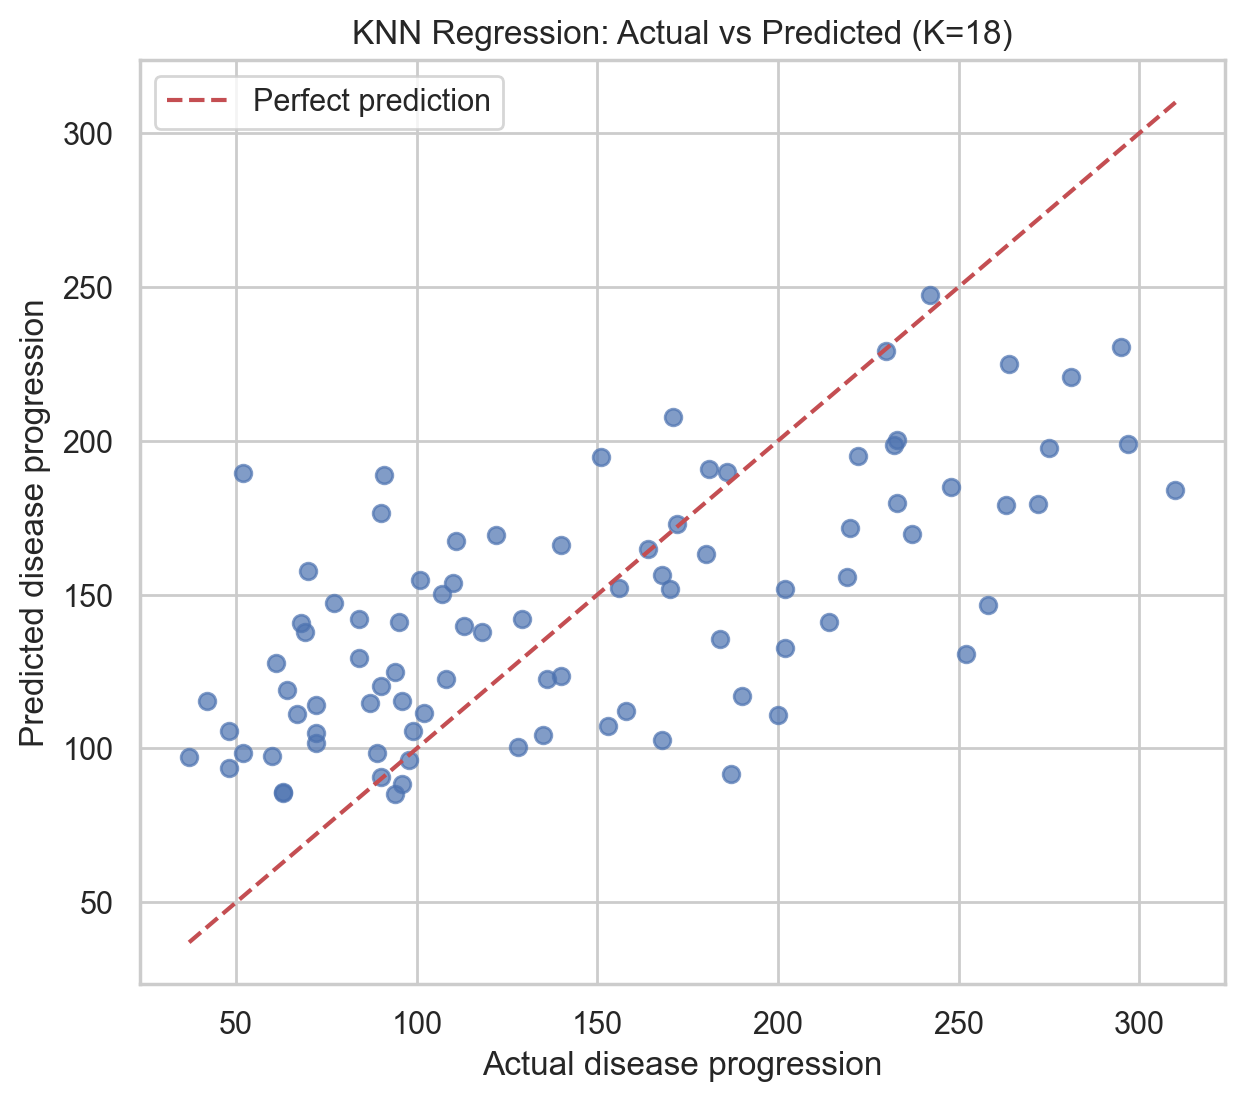

In [38]:
final_reg=KNeighborsRegressor(n_neighbors=best_k_reg)
final_reg.fit(Xr_train_scaled,yr_train)
yr_best=final_reg.predict(Xr_test_scaled)
print(f"Test MAE  : {mean_absolute_error(yr_test,yr_best):.4f}")
print(f"Test RMSE : {np.sqrt(mean_squared_error(yr_test,yr_best)):.4f}")
print(f"Test R2   : {r2_score(yr_test,yr_best):.4f}")

plt.figure(figsize=(7,6))
plt.scatter(yr_test,yr_best,alpha=0.7)
plt.plot([yr_test.min(),yr_test.max()],[yr_test.min(),yr_test.max()],"r--",label="Perfect prediction")
plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title(f"KNN Regression: Actual vs Predicted (K={best_k_reg})")
plt.legend()
plt.show()